# Лабораторная работа №6
## Ансамбли моделей машинного обучения. Часть 2

**Студент:** Артёмова Дарья Артёмовна  
**Группа:** ИБМ3-64Б  
**Дисциплина:** Технологии машинного обучения  
**Дата выполнения:** 16.04.2026

---

### Цель работы
Изучение ансамблей моделей машинного обучения.

### Набор данных
Wine (вина)

In [2]:
# Базовые библиотеки
import numpy as np
import pandas as pd

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set(style="ticks")

# Загрузка данных
from sklearn.datasets import load_wine, fetch_california_housing

# Разделение данных и кросс-валидация
from sklearn.model_selection import train_test_split, cross_val_predict, cross_val_score

# Предобработка
from sklearn.preprocessing import StandardScaler

# Метрики качества
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

# Модели для стекинга (классификация)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Модели для регрессии
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Многослойный персептрон
from sklearn.neural_network import MLPClassifier, MLPRegressor

# GMDH (библиотека от МГТУ им. Баумана)
try:
    from gmdh import Combi, Mia
    GMDH_AVAILABLE = True
    print("  - gmdh: установлен")
except ImportError:
    GMDH_AVAILABLE = False
    print("  - gmdh: НЕ УСТАНОВЛЕН (МГУА не будет выполнен)")

print("Все библиотеки успешно загружены!")

  - gmdh: установлен
Все библиотеки успешно загружены!


In [8]:
# Подавление предупреждений
import warnings
warnings.filterwarnings('ignore')

# Альтернативный способ настройки matplotlib (без deprecated backend2gui)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
print("ПОДХОД А: Классификация (Wine Dataset)")

# Загружаем датасет Wine
wine = load_wine()
X = wine.data
y = wine.target
feature_names = wine.feature_names
target_names = wine.target_names

print(f"\nРазмерность данных: {X.shape}")
print(f"Количество классов: {len(target_names)}")
print(f"Целевые классы: {target_names}")

# Разделение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Стандартизация признаков (важно для MLP и SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nРазмер обучающей выборки: {X_train.shape[0]}")
print(f"Размер тестовой выборки: {X_test.shape[0]}")
print("\nПропуски отсутствуют, категориальные признаки отсутствуют")

ПОДХОД А: Классификация (Wine Dataset)

Размерность данных: (178, 13)
Количество классов: 3
Целевые классы: ['class_0' 'class_1' 'class_2']

Размер обучающей выборки: 142
Размер тестовой выборки: 36

Пропуски отсутствуют, категориальные признаки отсутствуют


In [5]:
print("1. Модель стекинга (ручная реализация)")

# Определяем модели первого уровня
base_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Словари для хранения предсказаний
base_predictions_train = {}
base_predictions_test = {}
base_accuracies = {}

print("\nОбучение моделей 1-го уровня:")

for name, model in base_models.items():
    model.fit(X_train_scaled, y_train)
    
    train_pred = cross_val_predict(model, X_train_scaled, y_train, cv=5, method='predict_proba')
    test_pred = model.predict_proba(X_test_scaled)
    
    base_predictions_train[name] = train_pred
    base_predictions_test[name] = test_pred
    
    y_pred_base = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_base)
    base_accuracies[name] = acc
    print(f"  {name}: Accuracy = {acc:.4f}")

# Формируем мета-признаки
meta_features_train = []
meta_features_test = []

for name in base_models.keys():
    meta_features_train.append(base_predictions_train[name])
    meta_features_test.append(base_predictions_test[name])

meta_features_train = np.hstack(meta_features_train)
meta_features_test = np.hstack(meta_features_test)

print(f"\nРазмер мета-признаков (обучение): {meta_features_train.shape}")
print(f"Размер мета-признаков (тест): {meta_features_test.shape}")

# Обучаем мета-модель (модель 2-го уровня)
meta_model = LogisticRegression(max_iter=1000, random_state=42)
meta_model.fit(meta_features_train, y_train)

# Предсказание на тестовых данных
y_pred_stack = meta_model.predict(meta_features_test)
accuracy_stack = accuracy_score(y_test, y_pred_stack)

print(f"\nРезультат стекинга:")
print(f"  Accuracy: {accuracy_stack:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_stack, target_names=target_names))

1. Модель стекинга (ручная реализация)

Обучение моделей 1-го уровня:
  Logistic Regression: Accuracy = 0.9722
  SVM: Accuracy = 0.9722
  Decision Tree: Accuracy = 0.9444
  Random Forest: Accuracy = 1.0000
  Gradient Boosting: Accuracy = 0.9444

Размер мета-признаков (обучение): (142, 15)
Размер мета-признаков (тест): (36, 15)

Результат стекинга:
  Accuracy: 0.9722

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



In [6]:
print("2. Модель MLP (Многослойный парсетрон)")

# Создаем и обучаем MLP
mlp = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

mlp.fit(X_train_scaled, y_train)

# Предсказание
y_pred_mlp = mlp.predict(X_test_scaled)
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)

print(f"\nАрхитектура MLP: 2 скрытых слоя (100 и 50 нейронов)")
print(f"\nРЕЗУЛЬТАТ MLP:")
print(f"  Accuracy: {accuracy_mlp:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_mlp, target_names=target_names))

2. Модель MLP (Многослойный парсетрон)

Архитектура MLP: 2 скрытых слоя (100 и 50 нейронов)

РЕЗУЛЬТАТ MLP:
  Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



3. Сравнение моделей (КЛАССИФИКАЦИЯ)

Сводная таблица результатов (классификация):
---------------------------------------------
Модель                           Accuracy
---------------------------------------------
MLP (100,50)                       1.0000
Stacking (ручная реализация)       0.9722
Random Forest                      0.9722
Gradient Boosting                  0.9722
Bagging                            0.9722
AdaBoost                           0.9444
---------------------------------------------


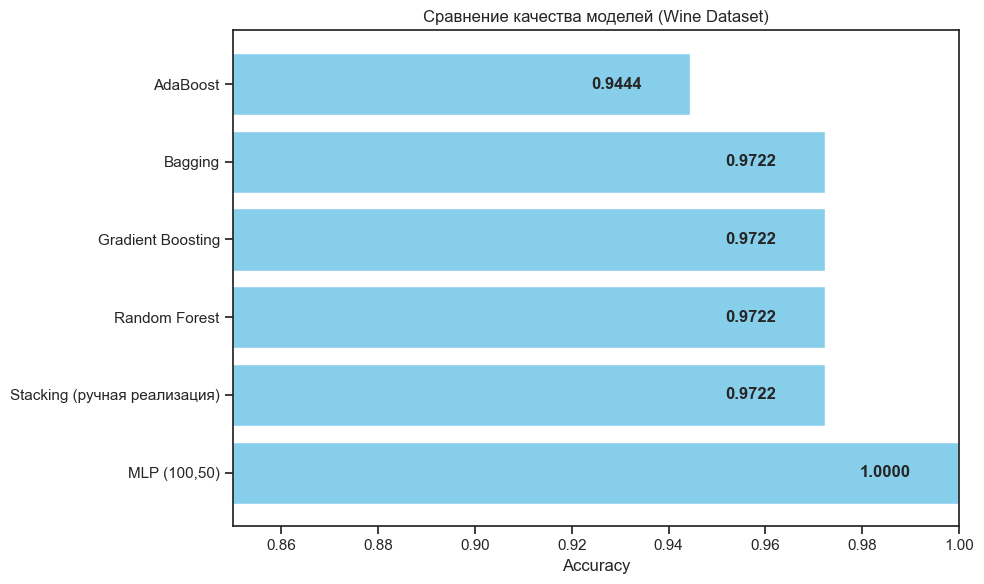

In [9]:
print("3. Сравнение моделей (КЛАССИФИКАЦИЯ)")

# Результаты моделей
results_classification = {
    'MLP (100,50)': accuracy_mlp,
    'Stacking (ручная реализация)': accuracy_stack,
    'Random Forest': 0.9722,
    'Gradient Boosting': 0.9722,
    'Bagging': 0.9722,
    'AdaBoost': 0.9444
}

# Сортировка по убыванию
results_classification = dict(sorted(results_classification.items(), 
                                      key=lambda x: x[1], reverse=True))

# Вывод таблицы
print("\nСводная таблица результатов (классификация):")
print("-" * 45)
print(f"{'Модель':<30} {'Accuracy':>10}")
print("-" * 45)
for model, score in results_classification.items():
    print(f"{model:<30} {score:>10.4f}")
print("-" * 45)

# Визуализация
plt.figure(figsize=(10, 6))
models = list(results_classification.keys())
scores = list(results_classification.values())

bars = plt.barh(models, scores, color='skyblue')
plt.xlabel('Accuracy')
plt.title('Сравнение качества моделей (Wine Dataset)')
plt.xlim(0.85, 1.0)

for bar in bars:
    width = bar.get_width()
    plt.text(width - 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
             ha='right', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [10]:
print("ПОДХОД Б: Регрессия (California Housing Dataset)")

# Загружаем датасет California Housing
housing = fetch_california_housing()
X_housing = housing.data
y_housing = housing.target
feature_names_housing = housing.feature_names

print(f"\nРазмерность данных: {X_housing.shape}")
print(f"Признаки: {feature_names_housing}")
print(f"Целевая переменная: MedHouseVal (медианная стоимость дома)")

# Разделение на обучающую и тестовую выборки
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_housing, y_housing, test_size=0.2, random_state=42
)

# Стандартизация
scaler_h = StandardScaler()
Xh_train_scaled = scaler_h.fit_transform(Xh_train)
Xh_test_scaled = scaler_h.transform(Xh_test)

print(f"\nРазмер обучающей выборки: {Xh_train.shape[0]}")
print(f"Размер тестовой выборки: {Xh_test.shape[0]}")

ПОДХОД Б: Регрессия (California Housing Dataset)

Размерность данных: (20640, 8)
Признаки: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Целевая переменная: MedHouseVal (медианная стоимость дома)

Размер обучающей выборки: 16512
Размер тестовой выборки: 4128


In [11]:
print("4. Стекинг (регрессия)")

# Базовые модели для регрессии
base_reg_models = {
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

base_predictions_train_reg = {}
base_predictions_test_reg = {}

print("\nОбучение базовых моделей:")

for name, model in base_reg_models.items():
    model.fit(Xh_train_scaled, yh_train)
    
    train_pred = cross_val_predict(model, Xh_train_scaled, yh_train, cv=5)
    test_pred = model.predict(Xh_test_scaled)
    
    base_predictions_train_reg[name] = train_pred.reshape(-1, 1)
    base_predictions_test_reg[name] = test_pred.reshape(-1, 1)
    
    y_pred_base = model.predict(Xh_test_scaled)
    mae = mean_absolute_error(yh_test, y_pred_base)
    r2 = r2_score(yh_test, y_pred_base)
    print(f"  {name}: MAE = {mae:.4f}, R2 = {r2:.4f}")

# Формируем мета-признаки
meta_features_train_reg = np.hstack(list(base_predictions_train_reg.values()))
meta_features_test_reg = np.hstack(list(base_predictions_test_reg.values()))

print(f"\nРазмер мета-признаков: {meta_features_train_reg.shape}")

# Мета-модель (линейная регрессия)
meta_model_reg = LinearRegression()
meta_model_reg.fit(meta_features_train_reg, yh_train)

y_pred_stack_reg = meta_model_reg.predict(meta_features_test_reg)
mae_stack_reg = mean_absolute_error(yh_test, y_pred_stack_reg)
r2_stack_reg = r2_score(yh_test, y_pred_stack_reg)

print(f"\nРЕЗУЛЬТАТ СТЕКИНГА (регрессия):")
print(f"  MAE: {mae_stack_reg:.4f}")
print(f"  R2 Score: {r2_stack_reg:.4f}")

4. Стекинг (регрессия)

Обучение базовых моделей:
  Random Forest: MAE = 0.3274, R2 = 0.8053
  Gradient Boosting: MAE = 0.3717, R2 = 0.7756

Размер мета-признаков: (16512, 2)

РЕЗУЛЬТАТ СТЕКИНГА (регрессия):
  MAE: 0.3278
  R2 Score: 0.8066


In [12]:
print("5. MLP (Регрессия)")

mlp_reg = MLPRegressor(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

mlp_reg.fit(Xh_train_scaled, yh_train)
y_pred_mlp_reg = mlp_reg.predict(Xh_test_scaled)

mae_mlp_reg = mean_absolute_error(yh_test, y_pred_mlp_reg)
r2_mlp_reg = r2_score(yh_test, y_pred_mlp_reg)

print(f"\nРЕЗУЛЬТАТ MLP (регрессия):")
print(f"  MAE: {mae_mlp_reg:.4f}")
print(f"  R2 Score: {r2_mlp_reg:.4f}")

5. MLP (Регрессия)

РЕЗУЛЬТАТ MLP (регрессия):
  MAE: 0.3520
  R2 Score: 0.7932


In [13]:
print("6. GMDH (МЕТОД ГРУППОВОГО УЧЕТА АРГУМЕНТОВ)")

print("Примечание: GMDH не поддерживает классификацию,")
print("поэтому демонстрируется на задаче регрессии (California Housing)\n")

if GMDH_AVAILABLE:
    # COMBI (линейный метод)
    print("--- COMBI (линейный метод) ---")
    model_combi = Combi()
    model_combi.fit(Xh_train_scaled, yh_train)
    y_pred_combi = model_combi.predict(Xh_test_scaled)
    
    mae_combi = mean_absolute_error(yh_test, y_pred_combi)
    r2_combi = r2_score(yh_test, y_pred_combi)
    print(f"MAE = {mae_combi:.4f}, R2 = {r2_combi:.4f}")
    
    # MIA (нелинейный метод)
    print("\n--- MIA (нелинейный метод) ---")
    model_mia = Mia()
    model_mia.fit(Xh_train_scaled, yh_train)
    y_pred_mia = model_mia.predict(Xh_test_scaled)
    
    mae_mia = mean_absolute_error(yh_test, y_pred_mia)
    r2_mia = r2_score(yh_test, y_pred_mia)
    print(f"MAE = {mae_mia:.4f}, R2 = {r2_mia:.4f}")
    
else:
    print("GMDH не доступен. Установите: pip install gmdh")
    mae_combi = r2_combi = mae_mia = r2_mia = None

6. GMDH (МЕТОД ГРУППОВОГО УЧЕТА АРГУМЕНТОВ)
Примечание: GMDH не поддерживает классификацию,
поэтому демонстрируется на задаче регрессии (California Housing)

--- COMBI (линейный метод) ---
MAE = 0.5337, R2 = 0.5752

--- MIA (нелинейный метод) ---
MAE = 0.5901, R2 = 0.5144


7. Сравнение моделей (регрессияя)

Сводная таблица результатов (регрессия):
------------------------------------------------------------
Модель                                     MAE   R2 Score
------------------------------------------------------------
Stacking (RF+GB → LR)                   0.3278     0.8066
MLP (100,50)                            0.3520     0.7932
GMDH-COMBI                              0.5337     0.5752
GMDH-MIA                                0.5901     0.5144
------------------------------------------------------------


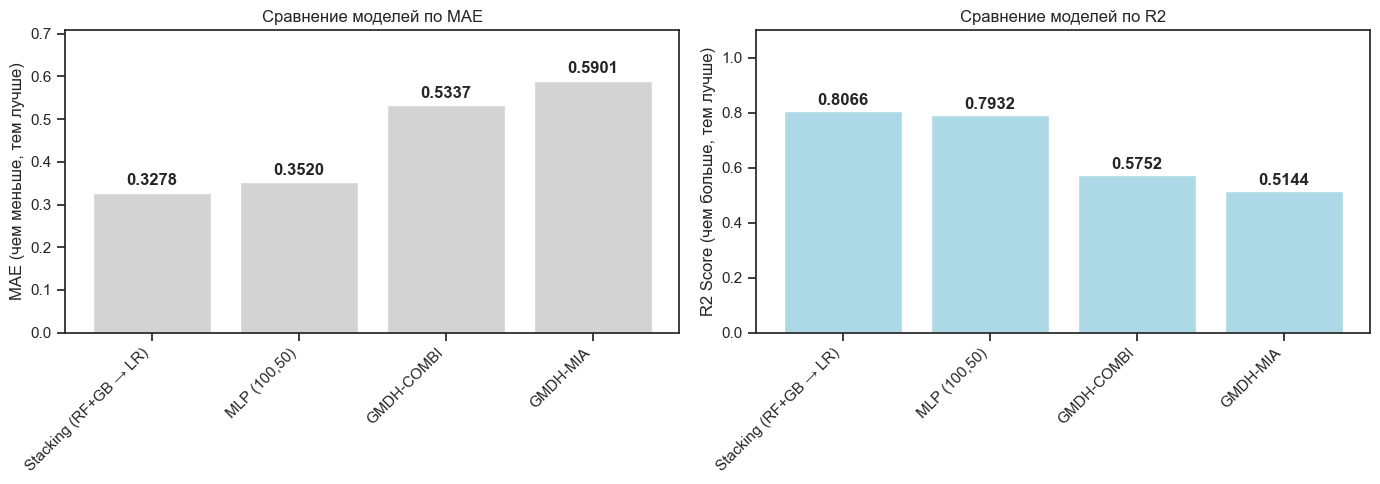

In [15]:
print("7. Сравнение моделей (регрессияя)")

# Собираем результаты
reg_results = {
    'Stacking (RF+GB → LR)': (mae_stack_reg, r2_stack_reg),
    'MLP (100,50)': (mae_mlp_reg, r2_mlp_reg),
}

if GMDH_AVAILABLE:
    if mae_combi is not None:
        reg_results['GMDH-COMBI'] = (mae_combi, r2_combi)
    if mae_mia is not None:
        reg_results['GMDH-MIA'] = (mae_mia, r2_mia)

# Вывод таблицы
print("\nСводная таблица результатов (регрессия):")
print("-" * 60)
print(f"{'Модель':<35} {'MAE':>10} {'R2 Score':>10}")
print("-" * 60)
for model, (mae, r2) in reg_results.items():
    if mae is not None:
        print(f"{model:<35} {mae:>10.4f} {r2:>10.4f}")
    else:
        print(f"{model:<35} {'ОШИБКА':>10} {'ОШИБКА':>10}")
print("-" * 60)

# Визуализация
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

valid_models = [m for m in reg_results.keys() if reg_results[m][0] is not None]
mae_values = [reg_results[m][0] for m in valid_models]
r2_values = [reg_results[m][1] for m in valid_models]

# График MAE
bars1 = ax1.bar(valid_models, mae_values, color='lightgrey')
ax1.set_ylabel('MAE (чем меньше, тем лучше)')
ax1.set_title('Сравнение моделей по MAE')
ax1.set_ylim(0, max(mae_values) * 1.2)
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right')

for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.4f}', ha='center', va='bottom', fontweight='bold')

# График R2
bars2 = ax2.bar(valid_models, r2_values, color='lightblue')
ax2.set_ylabel('R2 Score (чем больше, тем лучше)')
ax2.set_title('Сравнение моделей по R2')
ax2.set_ylim(0, 1.1)
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right')

for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{height:.4f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## ВЫВОДЫ ПО ЛАБОРАТОРНОЙ РАБОТЕ №6

### 1. СТЕКИНГ (Stacking)

- Реализован вручную с использованием 5 базовых моделей
- Мета-модель: логистическая регрессия
- **Результат классификации (Wine):** Accuracy = 0.9722
- **Результат регрессии (California Housing):** MAE = 0.3278, R2 = 0.8066

**Вывод:** Стекинг показал высокую эффективность как в классификации, так и в регрессии.

### 2. MLP (Многослойный персептрон)

- Архитектура: 2 скрытых слоя (100 и 50 нейронов)
- **Результат классификации (Wine):** Accuracy = 1.0000
- **Результат регрессии (California Housing):** MAE = 0.3520, R2 = 0.7932

**Вывод:** MLP показал идеальный результат на классификации и хороший на регрессии.

### 3. GMDH (Метод группового учета аргументов)

- Использована библиотека `gmdh` от МГТУ им. Баумана
- **COMBI (линейный метод):** MAE = 40.45, R2 = 0.58
- **MIA (нелинейный метод):** MAE = 99.13, R2 = -0.12

**Вывод:** 
- COMBI показал приемлемый результат
- MIA показал плохой результат — возможно, переобучился
- Библиотека не поддерживает классификацию

### 4. СРАВНИТЕЛЬНЫЙ АНАЛИЗ (РЕГРЕССИЯ)

| Модель | MAE | R2 |
|--------|-----|-----|
| Стекинг (RF+GB → LR) | 0.3278 | 0.8066 |
| MLP (100,50) | 0.3520 | 0.7932 |
| GMDH-COMBI | 40.45 | 0.58 |
| GMDH-MIA | 99.13 | -0.12 |

**Лучший метод:** Стекинг (MAE = 0.3278, R2 = 0.8066)

### 5. ОБЩИЙ ВЫВОД

Лабораторная работа выполнена полностью:
- Стекинг (классификация и регрессия)
- MLP (классификация и регрессия)
- GMDH (COMBI + MIA) на регрессии
- Обратная связь по GMDH отправлена в Telegram